In [ ]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [1]:
import h5py
import pickle
import scipy
import numpy as np
import seaborn as sns
# sns.set()
sns.set_style("whitegrid", {'axes.grid' : False})
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches
from f2_utils import *
import time_in_each_roi

/home/wx2203/anaconda3/lib/python3.7/site-packages/pandas/compat/_optional.py:138: UserWarning: Pandas requires version '2.7.0' or newer of 'numexpr' (version '2.6.9' currently installed).
  warnings.warn(msg, UserWarning)
/home/wx2203/anaconda3/lib/python3.7/site-packages/dask/config.py:168: YAMLLoadWarning: calling yaml.load() without Loader=... is deprecated, as the default Loader is unsafe. Please read https://msg.pyyaml.org/load for full details.
  data = yaml.load(f.read()) or {}


In [2]:
# neural_root = '/home/wx2203/Weihao/data_locker/step_2/'
prefix = '/mnt/staging/' # or 
step_0_root = str(STEPS / "step_0") + "/"
step_1_root = str(STEPS / "step_1") + "/"
step_2_root = str(STEPS / "step_2") + "/"
step_3_root = str(STEPS / "step_3") + "/"

fetch_path_S1 = str(PREPARES / "index-S1") + "/"
fetch_path_M2 = str(PREPARES / "index-M2") + "/"
fetch_path_M1 = str(FIGURES / "figure5") + "/"
fetch_path_extra = str(PREPARES / "index-extra") + "/"

data_root =  str(PREPARES / "epochs-rest-to-running") + "/"
figure_config_root = str(PREPARES / "config") + "/"

mouse='cm125'

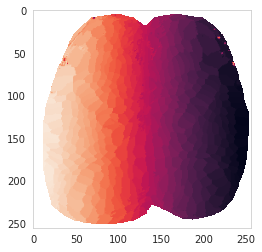

In [3]:
with h5py.File(step_0_root+mouse+'/idx_sorted_500_'+mouse+'.mat','r') as f_idx:
    IDX_sorted = np.array(f_idx['IDX_sorted']).T
    IDX_sorted = IDX_sorted.astype(float)
    IDX_sorted[IDX_sorted==0]='nan'
    
    num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1))))
    props = regionprops(IDX_sorted.astype(int))
    node_coords = [props[i].centroid for i in range(len(props))]
    node_coords = np.asarray(node_coords, dtype=np.float32)
    
    mask = IDX_sorted >0
    mask = mask.astype(float)
    mask[mask==0]='nan'
    
plt.imshow(IDX_sorted)

In [5]:
sensory_ind = load_pickle(fetch_path_S1+'inferred_brightest_ind_'+mouse)
# motor_ind = load_pickle(fetch_path_M2+'brightest_frontline_ind-'+mouse)
# mouth_S1_ind = sensory_ind['mouth']
# extra_ind = load_pickle(fetch_path_extra+'extra_ind_'+mouse)
# extra_extra_ind = load_pickle(fetch_path_extra+'extra_extra_ind_'+mouse)
# sensory_ind['LM']=sensory_ind['mouth']
# sensory_ind['RM']=extra_extra_ind['right_mouth_sensory']


In [6]:
load_list = ['norm_M_jrgeco', 'norm_M_rotf', 'norm_M_face_pc', 'norm_M_body_pc', 'norm_M_pupil_pc_norm', 
 'norm_M_whisk_vel_norm', 'norm_M_nose_vel_norm', 'norm_M_LFP_vel_norm', 'norm_M_RFP_vel_norm',
 'M_day_label', 'M_is_groom', 'M_ind', 'norm_M_mirrorRFP_vel_norm', 'norm_M_mirrorLFP_vel_norm', 
 'norm_M_mirrorRHP_vel_norm', 'norm_M_mirrorLHP_vel_norm']

f = scipy.io.loadmat(data_root+'final_'+mouse+'_norm.mat')

for item in load_list:
    exec("{}=np.squeeze(f['{}'])".format(item,item))
T_PRE=200;
T_POST=300;
T=T_PRE+T_POST

In [7]:
choice_body_part_dict = {0:'RHP',1:'RFP',2:'RW',3:'RV',
                         4:'RM_M2',5:'RFP_M2',6:'LatM'}
choice_dict = {0:316,1:400,2:sensory_ind['RW'],3:406,4:[],5:[],6:418}

In [8]:
def make_spectrogram(mean_of_regions,fs):
    ss = mean_of_regions.shape
    t_ss = ss[0] # time 650
    num_bouts = ss[1] # bouts
    
    # concat 
    # CAUTION: TRANSPOSE HERE IS IMPORTANT
    x = mean_of_regions.transpose().reshape((1,-1))
    # NOW TIME COURSES ARE CONCATED
    long_ss = x.shape[1]
    
    f, t, Sxx = signal.spectrogram(x, fs ,noverlap=18,nperseg=30,nfft=300)
    Sxx = np.squeeze(Sxx)
    num_freq_bins = Sxx.shape[0]
    
    Slinn = np.zeros((num_freq_bins,long_ss))
    for i in range(num_freq_bins):
        Slinn[i,:] = np.interp(np.divide(range(long_ss),20),t,np.abs(Sxx[i,:]));
    Slinn = Slinn.reshape((num_freq_bins,num_bouts,t_ss))
    return Slinn,f

In [10]:

load_filename = data_root+'final_'+mouse+'_MM_full.h5'
# Load and baseline-subtract in blocks of 16 rows. The original built a second
# full-size array here (np.array(...), then MM_jrgeco - np.mean(...)), so it needed two
# copies of the stack live at once: 2 x 31.7 GB = 63.5 GB for cm125, which OOM-kills a
# 48 GB machine (exit 137). This holds one 31.7 GB array plus one ~2 GB block, and
# reads stay sequential; measured on an M4 Pro it finishes in 49 s with 6.4 GB max
# resident.
# Bit-identical to the original: np.array_equal(..., equal_nan=True) is True, because
# blocking along axis 0 leaves the axis-2 reduction untouched. See
# a memory-safe chunked loader.
with h5py.File(load_filename, 'r') as hf:
    dset = hf['MM_jrgeco']
    MM_jrgeco = np.empty(dset.shape, dtype=dset.dtype)
    for i_x0 in range(0, dset.shape[0], 16):
        blk = dset[i_x0:i_x0 + 16]
        MM_jrgeco[i_x0:i_x0 + 16] = blk - np.mean(blk[:,:,T_PRE-100:T_PRE,:],2)[:,:,np.newaxis,:]
    del blk, dset

In [11]:
dict_seed_ROI_xy_mice  = load_pickle(figure_config_root+'dict_seed_ROI_xy_mice')

list_choice_M2_l_n_r = ['RFP','RM','RW','RHP','LFP','LM','LW','LHP']
seed_ROI_xy = dict_seed_ROI_xy_mice[mouse]

jrgeco2plot_M2 = {};node_coords_M2 = {}
for i_bdp in range(8):
    bdp = list_choice_M2_l_n_r[i_bdp]
    y_top_left = seed_ROI_xy[bdp]['y_top_left']
    y_botton_right = seed_ROI_xy[bdp]['y_botton_right']
    x_top_left =seed_ROI_xy[bdp]['x_top_left']
    x_botton_right=seed_ROI_xy[bdp]['x_botton_right']
    node_coords_M2[bdp] = np.array([(y_top_left+y_botton_right)/2,(x_top_left+x_botton_right)/2])
    small_roi_tcs = np.nanmean(np.nanmean(
        MM_jrgeco[x_top_left:x_botton_right,y_top_left:y_botton_right],0),0)
    jrgeco2plot_M2[bdp] = small_roi_tcs
    
H_jrgeco_new_bsl=getH_4D(MM_jrgeco,IDX_sorted)

In [12]:
jrgeco2plot ={}
for i_bdp in range(7):
    bdp = choice_body_part_dict[i_bdp]
    ind = choice_dict[i_bdp]
    if len(bdp.split('_'))==1:
        jrgeco2plot[bdp]=H_jrgeco_new_bsl[ind,:,:]
    else:
        if bdp.split('_')[1] == 'M2':
            jrgeco2plot[bdp] = jrgeco2plot_M2[bdp.split('_')[0]]
            
        else:
            jrgeco2plot[bdp] = jrgeco2plot[bdp.split('_')[0]]
            


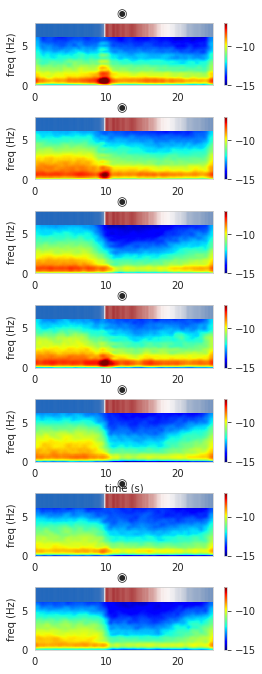

In [13]:
x = range(norm_M_body_pc.shape[0])
my_xticks = np.divide(range(norm_M_body_pc.shape[0]),20)
y = range(norm_M_body_pc.shape[1])
my_yticks = range(norm_M_body_pc.shape[1])

dict_slinn,dict_f = {},{}

plt.figure(figsize=(4,15))
for i_bdp in range(7):
    bdp = choice_body_part_dict[i_bdp]
    ind = choice_dict[i_bdp]
    # params = {"text.color" : colors[i]}
    # plt.rcParams.update(params)
    plt.subplot(9,1,i_bdp+1)
    
    Slinn,f = make_spectrogram(jrgeco2plot[bdp],fs=20)
    dict_slinn[bdp] = Slinn
    dict_f[bdp]=f
    
#         plt.pcolormesh(x, f, np.log(np.mean(Slinn,axis=1)),cmap='vlag')
    plt.pcolormesh(x, f, np.log(np.mean(Slinn,axis=1)),cmap='jet',vmin=-15,vmax=-7)
    plt.colorbar()
    plt.xticks(np.array(x[::200],dtype='int'), 
           np.array(my_xticks[::200],dtype='int'));

#         plt.xticks([]);plt.yticks([])
    plt.ylim([0,7.9])
    plt.xlim([0,500])

    beh2plot = norm_M_body_pc
    avg = np.mean(beh2plot,axis=1)
    avg = normalize(avg)
#         plt.scatter(range(len(avg)),np.ones((len(avg)))*0.11+11.2,marker="|",s=950,c=avg,cmap='magma')
    plt.scatter(range(len(avg)),np.ones((len(avg)))*0.11+8,marker="|",s=1050,c=avg,cmap='vlag')
    plt.title('◉ ')
    plt.ylabel('freq (Hz)')
    if i_bdp==4:
        plt.xlabel('time (s)')
plt.subplots_adjust(hspace=0.5)



In [16]:
spectrogram_dict ={'dict_slinn':dict_slinn,
                  'dict_f':dict_f}

In [ ]:
save_path = str(FIGURES / "figure2") + "/"
filename=save_path+'figure2_avg_spectrogram.pickle'
save_pickle(spectrogram_dict,filename)


